#Data Analytics (DA)
##Module-End -5
Python DA Assignment 2-Data Visualization

#Problem Statement
In this project,i need to act as a data analyst to clean, analyze, and visualize taxi data. You will handle
missing values, explore trends, and create visualizations to gain insights into fare, distance, and
customer behavior using Pandas, Matplotlib, and Seaborn.

In [1]:
import seaborn as sns

# Load the taxi dataset
df = sns.load_dataset("taxis")

# Display the first 5 rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
# Check missing values in each column
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [3]:
# Fill missing payment values using the mode
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

# Remove rows with missing location information
df = df.dropna(subset=[
    'pickup_zone',
    'dropoff_zone',
    'pickup_borough',
    'dropoff_borough'
])

# Check missing values again
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


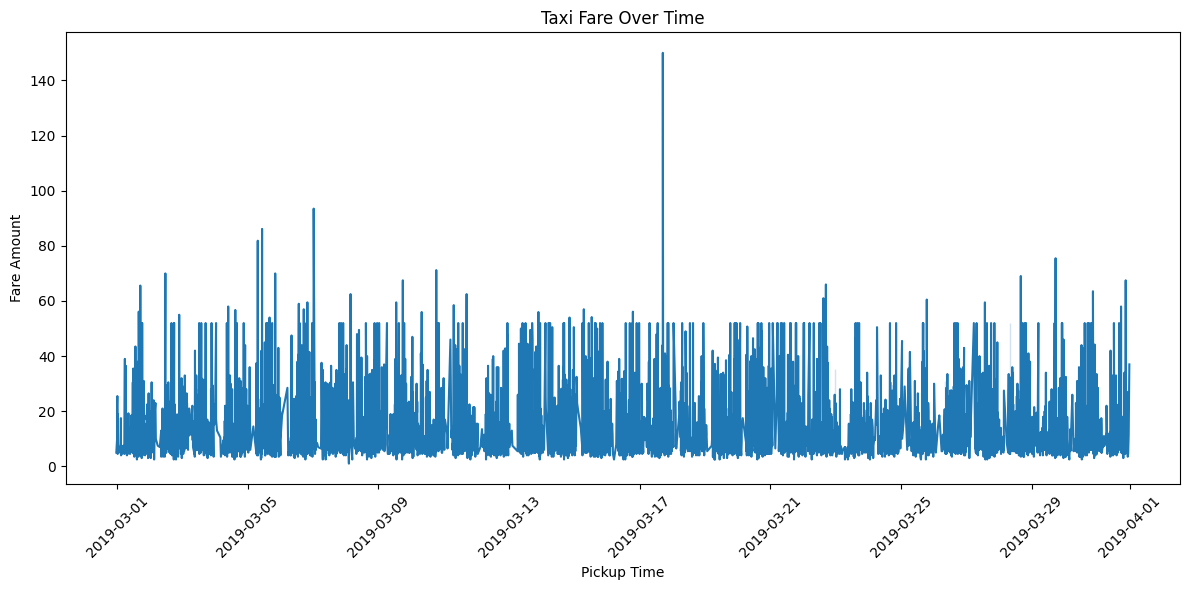

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort the data by pickup time
df = df.sort_values('pickup')

# Create a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(data=df, x='pickup', y='fare')

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

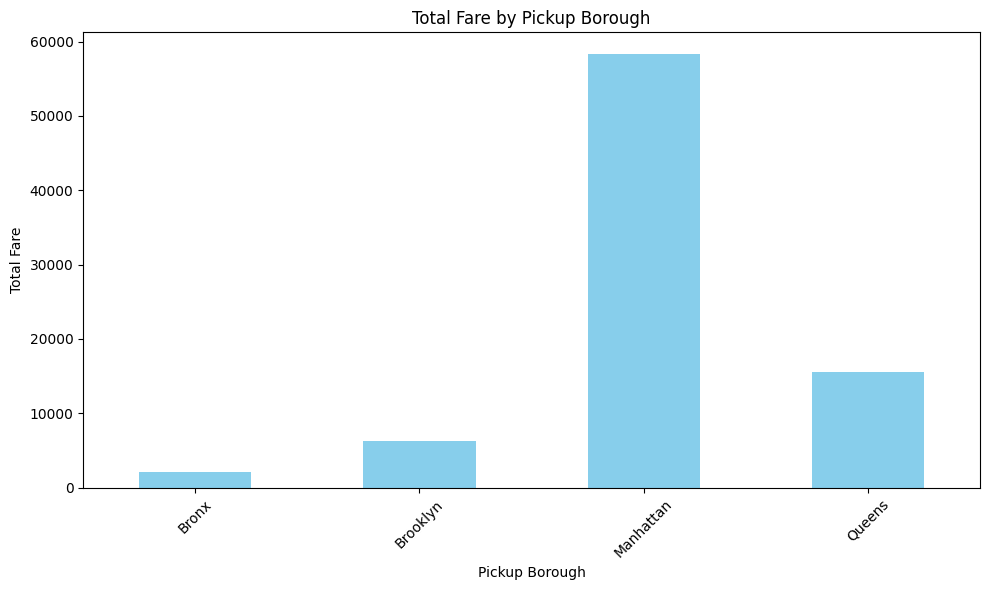

In [5]:
# Calculate total fare for each pickup borough
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create a bar chart
plt.figure(figsize=(10, 6))

borough_fare.plot(kind='bar', color='skyblue')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

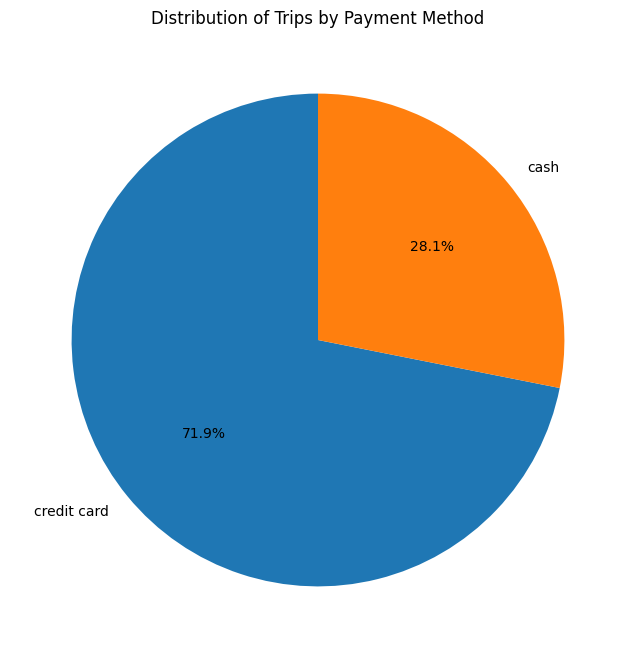

In [6]:
# Count the number of trips for each payment method
payment_counts = df['payment'].value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.show()

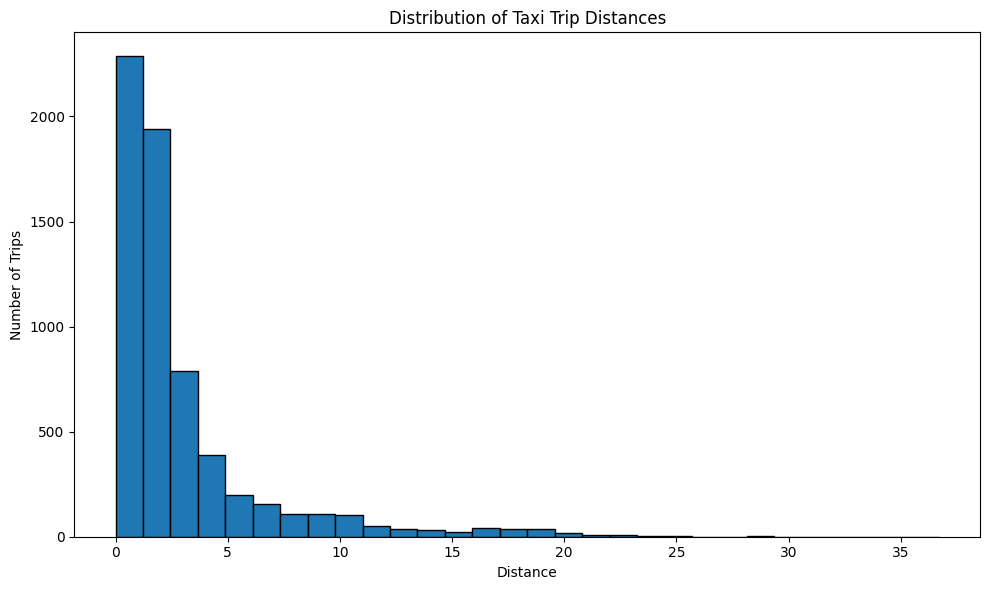

In [7]:
# Create a histogram for taxi trip distances
plt.figure(figsize=(10, 6))

plt.hist(df['distance'], bins=30, edgecolor='black')

plt.title('Distribution of Taxi Trip Distances')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')

plt.tight_layout()
plt.show()

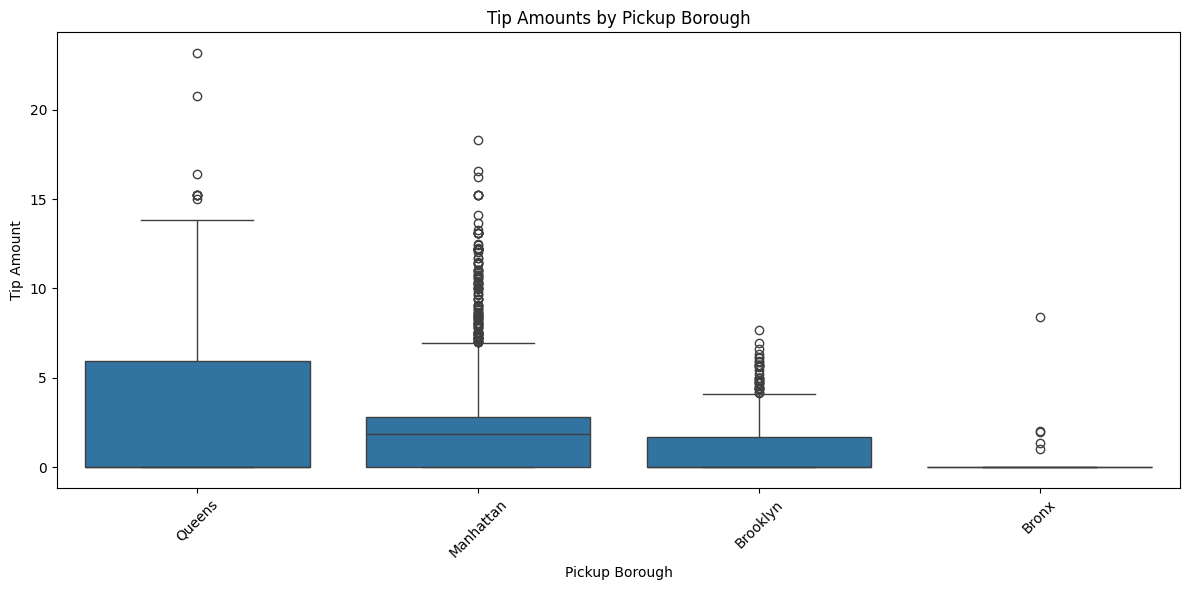

In [8]:
# Create a box plot
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='pickup_borough', y='tip')

plt.title('Tip Amounts by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()c

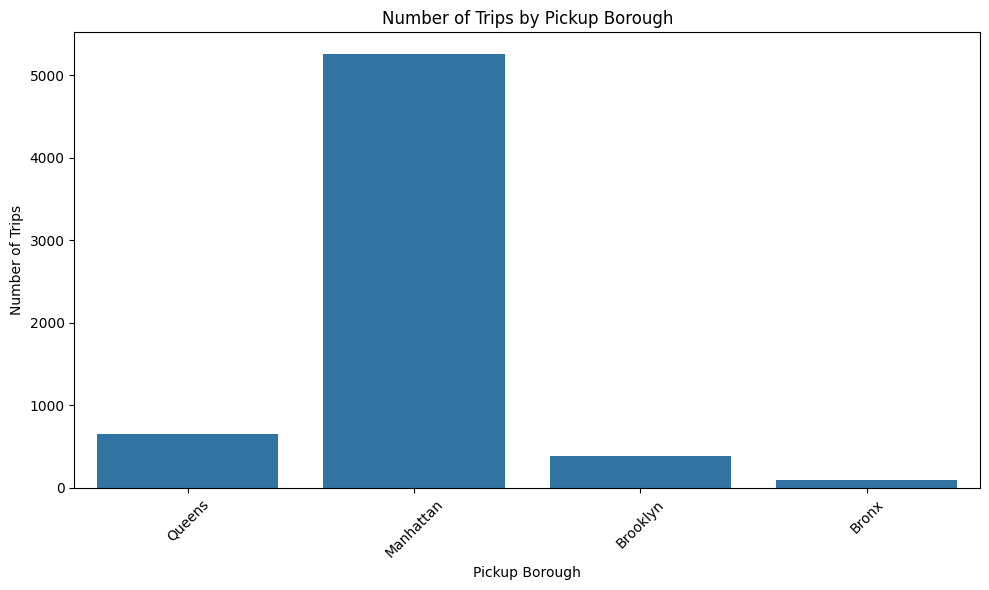

In [9]:
# Create a count plot
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

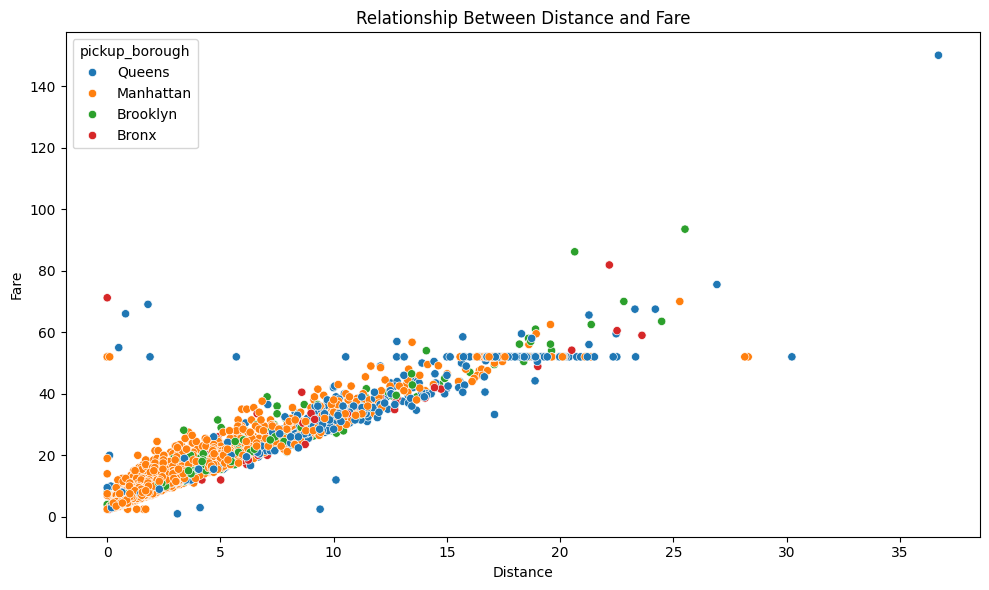

In [10]:
# Create a scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

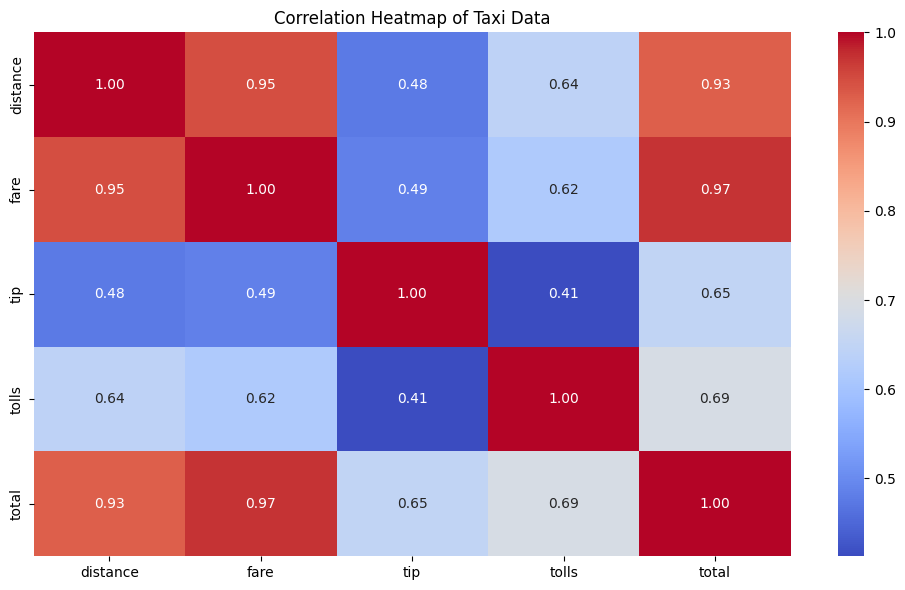

In [11]:
# Select numerical columns
numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation
correlation = numeric_data.corr()

# Create a heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Taxi Data')
plt.tight_layout()
plt.show()

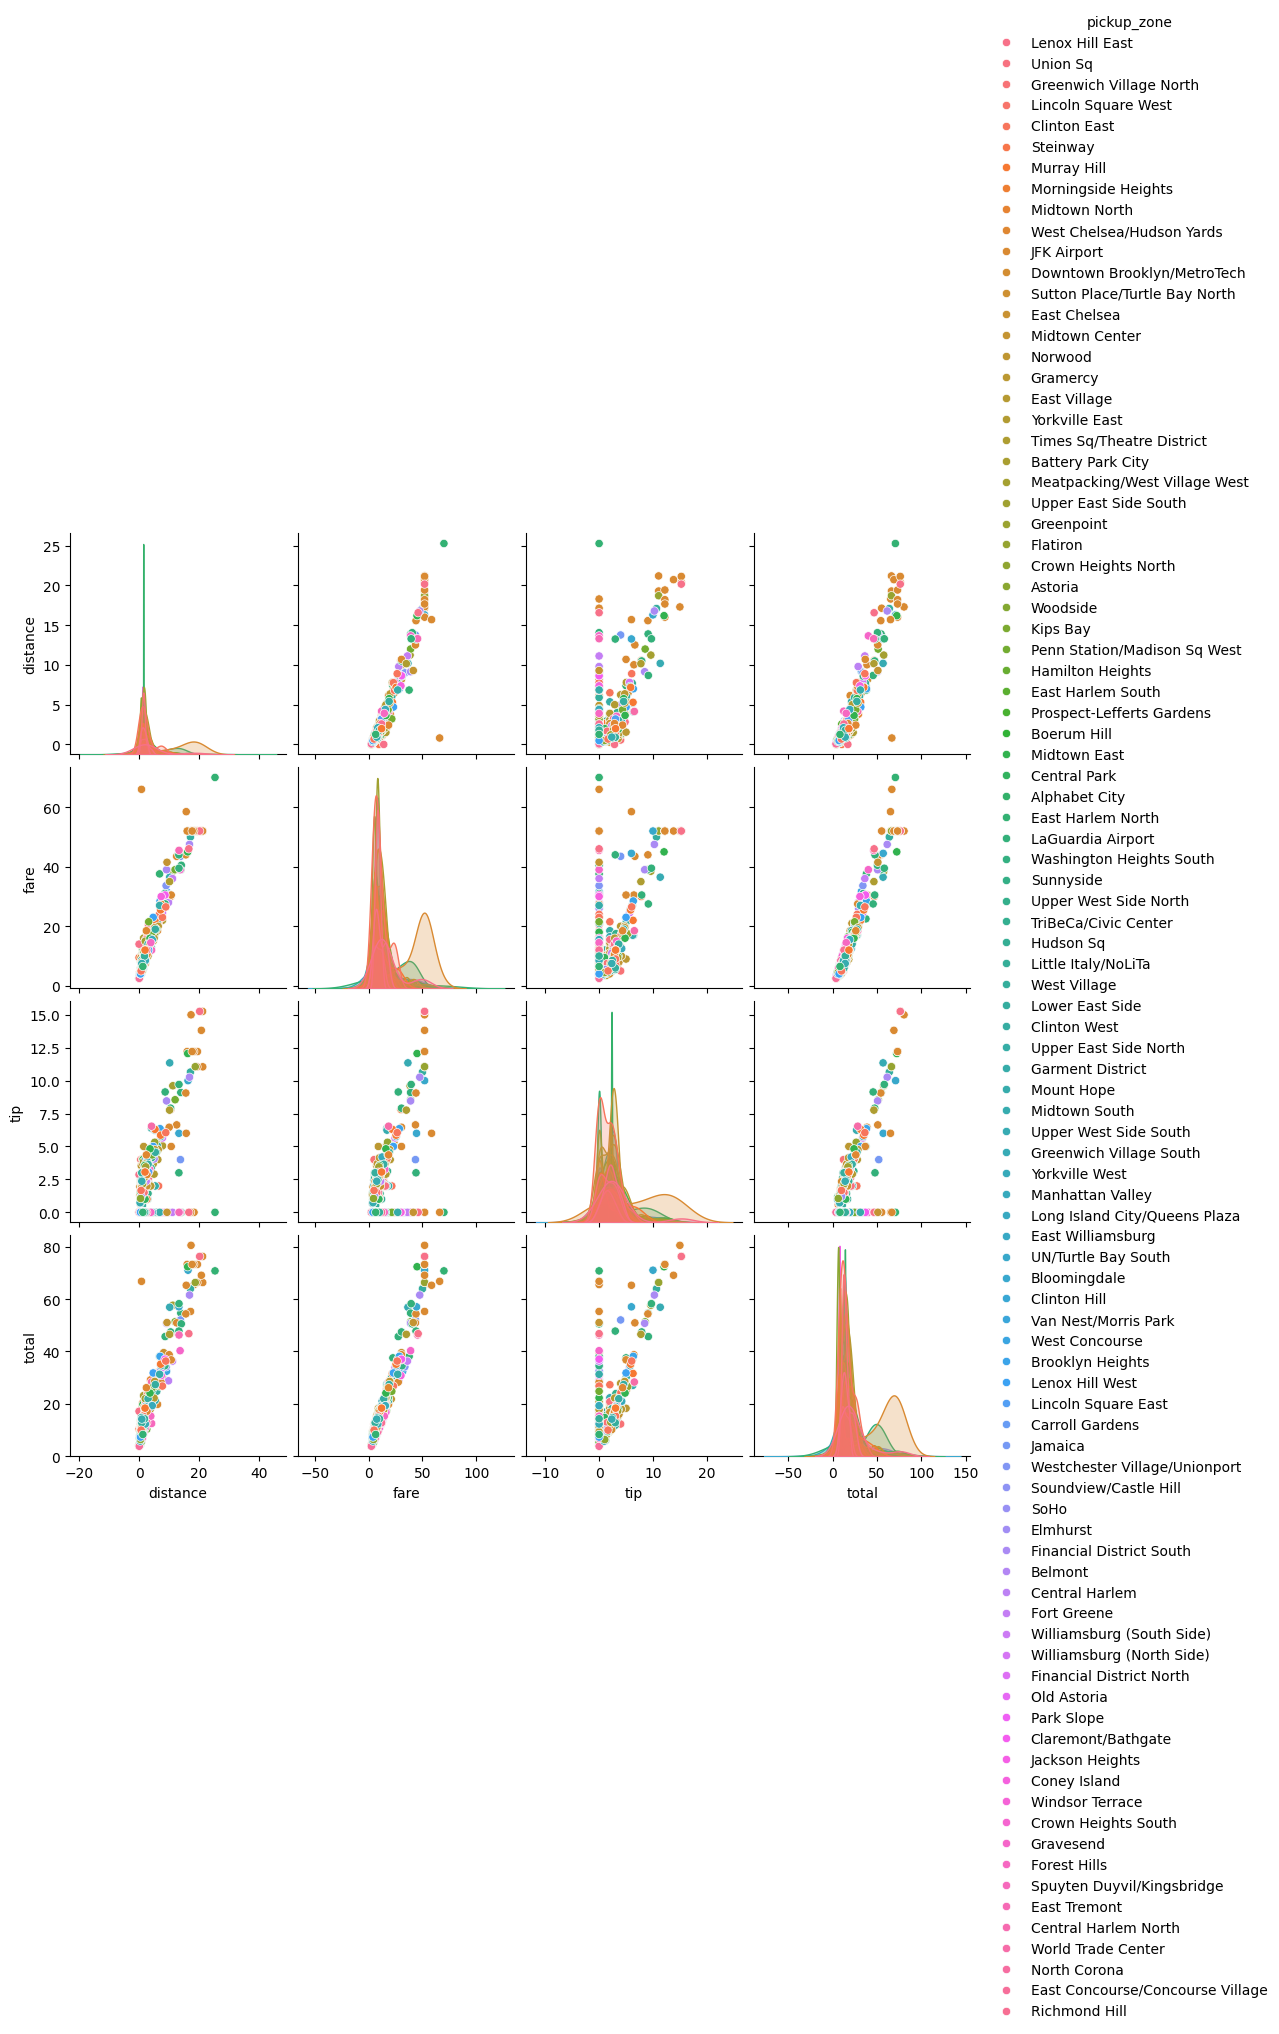

In [12]:
# Select columns for pair plot
pair_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

# Take a sample of 500 rows for faster plotting
pair_data = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

# Create pair plot
sns.pairplot(
    pair_data,
    hue='pickup_zone'
)

plt.show()

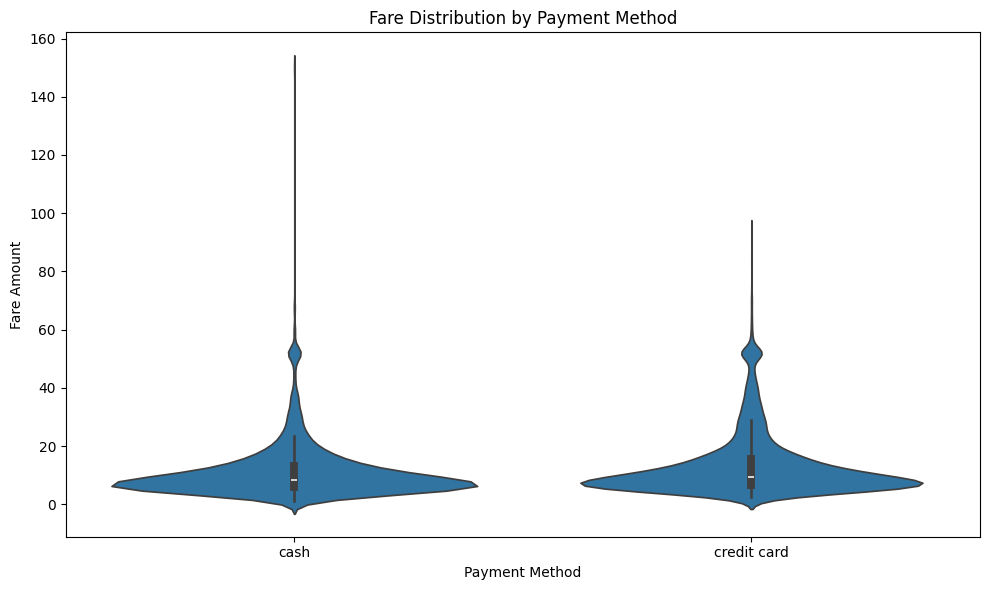

In [13]:
# Create a violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.tight_layout()
plt.show()